# AAPL Stock Price Forecasting with a GRU–CNN GAN

This notebook implements a Generative Adversarial Network (GAN) for next-day AAPL adjusted closing price forecasting. The model uses a 20-day lookback window with 14 input features, a three-layer GRU generator (1024/512/256 hidden units), and a CNN discriminator.

The generator predicts a price adjustment relative to the most recent known adjusted closing price. The final forecast is calculated by adding this adjustment to the previous day's price, with both values represented in the scaled price space.

The model is trained using adversarial loss without an additional supervised loss term (SUPERVISED_WEIGHT = 0.0). It uses the existing preprocessed data and NumPy arrays, and saves experimental outputs to a separate directory.

## 1 · Imports and paths

In [16]:
import os, json, pickle, time, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
try:
    import tensorflow as tf
    from tensorflow.keras import layers, Model
except ImportError as e:
    raise ImportError('TensorFlow is missing. Install in a compatible environment: pip install tensorflow') from e

SEED=42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
ROOT=Path.cwd()
DATA_DIR=ROOT/'gan_ready'
if not (DATA_DIR/'X_train.npy').exists():
    raise FileNotFoundError(f'GAN arrays missing in {DATA_DIR}. Run preprocessing notebook first.')
MODEL_DIR=DATA_DIR/'gan_models_20day_previous_close_only'; MODEL_DIR.mkdir(parents=True,exist_ok=True)
EPOCHS=165
BATCH_SIZE=128
LR=0.00016
SUPERVISED_WEIGHT=0.0
GRU_UNITS=(1024,512,256) # Original reference architecture; very heavy on CPU
SAVE_EVERY=15
print('TensorFlow:',tf.__version__,'| Data:',DATA_DIR.resolve())

TensorFlow: 2.11.1 | Data: /Users/my/Desktop/TWO-LSTM/FinBert_LSTMGRU_GAN/finbert/notebooks/gan_ready


## 2 · Load and validate GAN-ready arrays

In [17]:
names=['X_train','X_test','y_train','y_test','yc_train','yc_test','index_train','index_test']
a={k:np.load(DATA_DIR/f'{k}.npy',allow_pickle=False) for k in names}
with open(DATA_DIR/'X_scaler.pkl','rb') as f: X_scaler=pickle.load(f)
with open(DATA_DIR/'y_scaler.pkl','rb') as f: y_scaler=pickle.load(f)
meta=json.loads((DATA_DIR/'metadata.json').read_text())
X_train,X_test=a['X_train'].astype('float32'),a['X_test'].astype('float32')
y_train,y_test=a['y_train'].astype('float32'),a['y_test'].astype('float32')
yc_train,yc_test=a['yc_train'].astype('float32'),a['yc_test'].astype('float32')
assert X_train.ndim==3 and X_test.shape[1:]==X_train.shape[1:]
assert y_train.shape==(len(X_train),1) and y_test.shape==(len(X_test),1)
assert yc_train.shape==(len(X_train),3,1) and yc_test.shape==(len(X_test),3,1)
assert all(np.isfinite(v).all() for v in [X_train,X_test,y_train,y_test,yc_train,yc_test])
assert a['index_train'].max()<a['index_test'].min(), 'Chronological split is invalid'
print('Train:',X_train.shape,y_train.shape,yc_train.shape)
print('Test :',X_test.shape,y_test.shape,yc_test.shape)
print('Target:',meta['target'],'| Features:',len(meta['features']))

Train: (165, 20, 14) (165, 1) (165, 3, 1)
Test : (47, 20, 14) (47, 1) (47, 3, 1)
Target: Target_Next_Adj_Close | Features: 14


## 3 · Generator: GRU (reference architecture, original 1024/512/256 architecture)

In [18]:
def make_generator_model(input_dim, output_dim, feature_size, units=GRU_UNITS):
    inp=layers.Input(shape=(input_dim,feature_size),name='feature_window')
    x=layers.GRU(units[0],return_sequences=True)(inp)
    x=layers.GRU(units[1],return_sequences=True)(x)
    x=layers.GRU(units[2])(x)
    x=layers.Dense(128)(x)
    x=layers.Dense(64)(x)
    out=layers.Dense(output_dim,name='next_close_scaled')(x)
    return Model(inp,out,name='GRU_Generator')

generator=make_generator_model(X_train.shape[1],1,X_train.shape[2])
generator.summary()

Model: "GRU_Generator"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 feature_window (InputLayer)  [(None, 20, 14)]         0         
                                                                 
 gru_3 (GRU)                 (None, 20, 1024)          3194880   
                                                                 
 gru_4 (GRU)                 (None, 20, 512)           2362368   
                                                                 
 gru_5 (GRU)                 (None, 256)               591360    
                                                                 
 dense_8 (Dense)             (None, 128)               32896     
                                                                 
 dense_9 (Dense)             (None, 64)                8256      
                                                                 
 next_close_scaled (Dense)   (None, 1)               

## 4 · Discriminator: Conv1D on candidate next price + 3 historical prices

In [19]:
def make_discriminator_model():
    inp=layers.Input(shape=(4,1),name='candidate_plus_3_history')
    x=layers.Conv1D(64,3,strides=2,padding='same')(inp)
    x=layers.LeakyReLU(alpha=0.01)(x)
    x=layers.Conv1D(128,5,strides=2,padding='same')(x)
    x=layers.LeakyReLU(alpha=0.01)(x)
    x=layers.Conv1D(256,5,strides=2,padding='same')(x)
    x=layers.LeakyReLU(alpha=0.01)(x)
    x=layers.Flatten()(x)
    x=layers.Dense(220,activation='relu')(x)
    x=layers.Dense(220,activation='relu')(x)
    out=layers.Dense(1,activation='sigmoid')(x)
    return Model(inp,out,name='CNN_Discriminator')

discriminator=make_discriminator_model()
discriminator.summary()

Model: "CNN_Discriminator"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 candidate_plus_3_history (I  [(None, 4, 1)]           0         
 nputLayer)                                                      
                                                                 
 conv1d_6 (Conv1D)           (None, 2, 64)             256       
                                                                 
 leaky_re_lu_6 (LeakyReLU)   (None, 2, 64)             0         
                                                                 
 conv1d_7 (Conv1D)           (None, 1, 128)            41088     
                                                                 
 leaky_re_lu_7 (LeakyReLU)   (None, 1, 128)            0         
                                                                 
 conv1d_8 (Conv1D)           (None, 1, 256)            164096    
                                                 

## 5 · GAN training loop (mini-batches, original adversarial-only objective)

In [20]:
class GAN:
    def __init__(self,generator,discriminator,lr=LR,supervised_weight=SUPERVISED_WEIGHT):
        self.generator=generator
        self.discriminator=discriminator
        self.g_optimizer = tf.keras.optimizers.Adam(learning_rate=lr)
        self.d_optimizer = tf.keras.optimizers.Adam(learning_rate=lr)
        self.bce=tf.keras.losses.BinaryCrossentropy(from_logits=False)
        self.mse=tf.keras.losses.MeanSquaredError()
        self.supervised_weight=supervised_weight

    @tf.function
    def train_step(self,x,y,yc):
        with tf.GradientTape() as gt, tf.GradientTape() as dt:
            # Only change: add the latest known close (same y_scaler scale) to the generator output.
            # The GRU now learns a scaled price adjustment, without changing its architecture.
            fake=yc[:, -1, :] + self.generator(x,training=True)
            real_input=tf.concat([tf.expand_dims(y,axis=-1),yc],axis=1)
            fake_input=tf.concat([tf.expand_dims(fake,axis=-1),yc],axis=1)
            real_score=self.discriminator(real_input,training=True)
            fake_score=self.discriminator(fake_input,training=True)
            d_loss=self.bce(tf.ones_like(real_score),real_score)+self.bce(tf.zeros_like(fake_score),fake_score)
            adv_loss=self.bce(tf.ones_like(fake_score),fake_score)
            pred_loss=self.mse(y,fake)
            g_loss = adv_loss + self.supervised_weight * pred_loss
        g_grad=gt.gradient(g_loss,self.generator.trainable_variables)
        d_grad=dt.gradient(d_loss,self.discriminator.trainable_variables)
        self.g_optimizer.apply_gradients(zip(g_grad,self.generator.trainable_variables))
        self.d_optimizer.apply_gradients(zip(d_grad,self.discriminator.trainable_variables))
        return d_loss,g_loss,adv_loss,pred_loss

    def train(self,x,y,yc,epochs=EPOCHS,batch_size=BATCH_SIZE):
        ds=tf.data.Dataset.from_tensor_slices((x,y,yc)).shuffle(len(x),seed=SEED,reshuffle_each_iteration=True).batch(batch_size)
        history=[]
        for epoch in range(1,epochs+1):
            start=time.time(); losses=[]
            for bx,by,bc in ds:
                losses.append([float(t.numpy()) for t in self.train_step(bx,by,bc)])
            mean=np.asarray(losses).mean(axis=0)
            history.append({'epoch':epoch,'D_loss':mean[0],'G_loss':mean[1],
                            'adversarial_loss':mean[2],'prediction_MSE_scaled':mean[3],
                            'seconds':time.time()-start})
            if epoch==1 or epoch%SAVE_EVERY==0 or epoch==epochs:
                print(f'Epoch {epoch:3d}/{epochs} | D={mean[0]:.4f} G={mean[1]:.4f} pred_MSE={mean[3]:.5f}')
                self.generator.save(str(MODEL_DIR / f"generator_epoch_{epoch:03d}.h5"),include_optimizer=False)
        return pd.DataFrame(history)

gan=GAN(generator,discriminator)
history=gan.train(X_train,y_train,yc_train)
history.to_csv(MODEL_DIR/'training_history.csv',index=False)
generator.save(MODEL_DIR/'generator_final.keras')
discriminator.save(MODEL_DIR/'discriminator_final.keras')

Epoch   1/165 | D=1.3863 G=0.6967 pred_MSE=0.04727
Epoch  15/165 | D=1.3873 G=0.6908 pred_MSE=0.53099
Epoch  30/165 | D=1.3869 G=0.6904 pred_MSE=0.21573
Epoch  45/165 | D=1.3862 G=0.6921 pred_MSE=0.23332
Epoch  60/165 | D=1.3862 G=0.6937 pred_MSE=0.68720
Epoch  75/165 | D=1.3857 G=0.6918 pred_MSE=0.41503
Epoch  90/165 | D=1.3867 G=0.6931 pred_MSE=0.21138
Epoch 105/165 | D=1.3865 G=0.6916 pred_MSE=0.09004
Epoch 120/165 | D=1.3863 G=0.6918 pred_MSE=0.06021
Epoch 135/165 | D=1.3833 G=0.7038 pred_MSE=0.93712
Epoch 150/165 | D=1.3869 G=0.6843 pred_MSE=0.08246
Epoch 165/165 | D=1.3865 G=0.6946 pred_MSE=0.11599


## 6 · Training curves

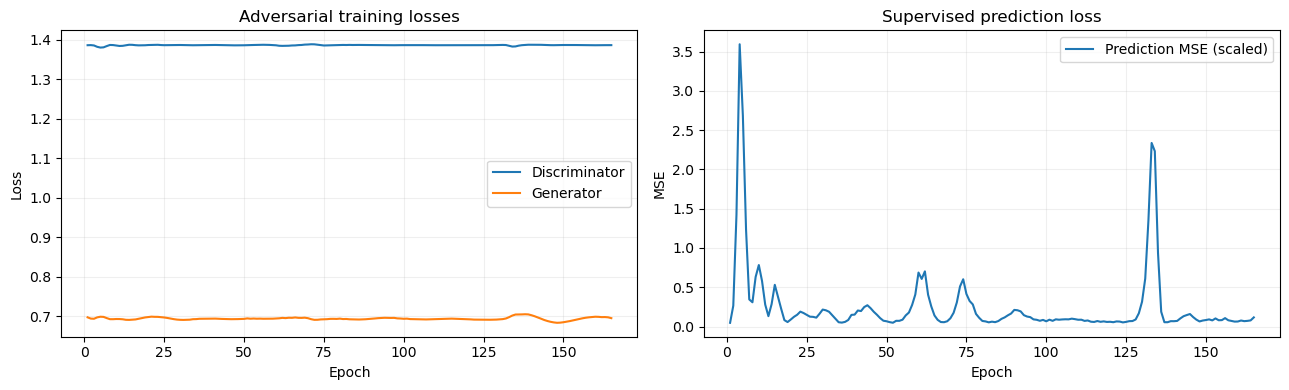

In [21]:
fig,ax=plt.subplots(1,2,figsize=(13,4))
ax[0].plot(history.epoch,history.D_loss,label='Discriminator')
ax[0].plot(history.epoch,history.G_loss,label='Generator')
ax[0].set(title='Adversarial training losses',xlabel='Epoch',ylabel='Loss');ax[0].legend();ax[0].grid(alpha=.2)
ax[1].plot(history.epoch,history.prediction_MSE_scaled,label='Prediction MSE (scaled)')
ax[1].set(title='Supervised prediction loss',xlabel='Epoch',ylabel='MSE');ax[1].legend();ax[1].grid(alpha=.2)
plt.tight_layout();plt.show()

## 7 · Inverse-scale predictions and chronological evaluation

In [22]:
def predict_original_scale(x, yc):
    # Match training: predicted next close = previous close + generator adjustment.
    z=yc[:, -1, :] + generator.predict(x,verbose=0)
    return y_scaler.inverse_transform(z).reshape(-1)

train_pred=predict_original_scale(X_train, yc_train)
test_pred=predict_original_scale(X_test, yc_test)
train_actual=y_scaler.inverse_transform(y_train).reshape(-1)
test_actual=y_scaler.inverse_transform(y_test).reshape(-1)

def metrics(actual,pred):
    return {'RMSE':float(np.sqrt(mean_squared_error(actual,pred))),
            'MAE':float(mean_absolute_error(actual,pred)),
            'MAPE_%':float(np.mean(np.abs((actual-pred)/actual))*100),
            'R2':float(r2_score(actual,pred))}

metrics_df=pd.DataFrame({'Train':metrics(train_actual,train_pred),
                         'Test':metrics(test_actual,test_pred)}).T
print(metrics_df.round(4).to_string())
metrics_df.to_csv(MODEL_DIR/'metrics.csv')

         RMSE     MAE  MAPE_%      R2
Train  8.0493  6.6043  2.3765  0.8876
Test   6.2230  5.2355  1.6055  0.7344


## 8 · Predicted vs actual next-day adjusted close

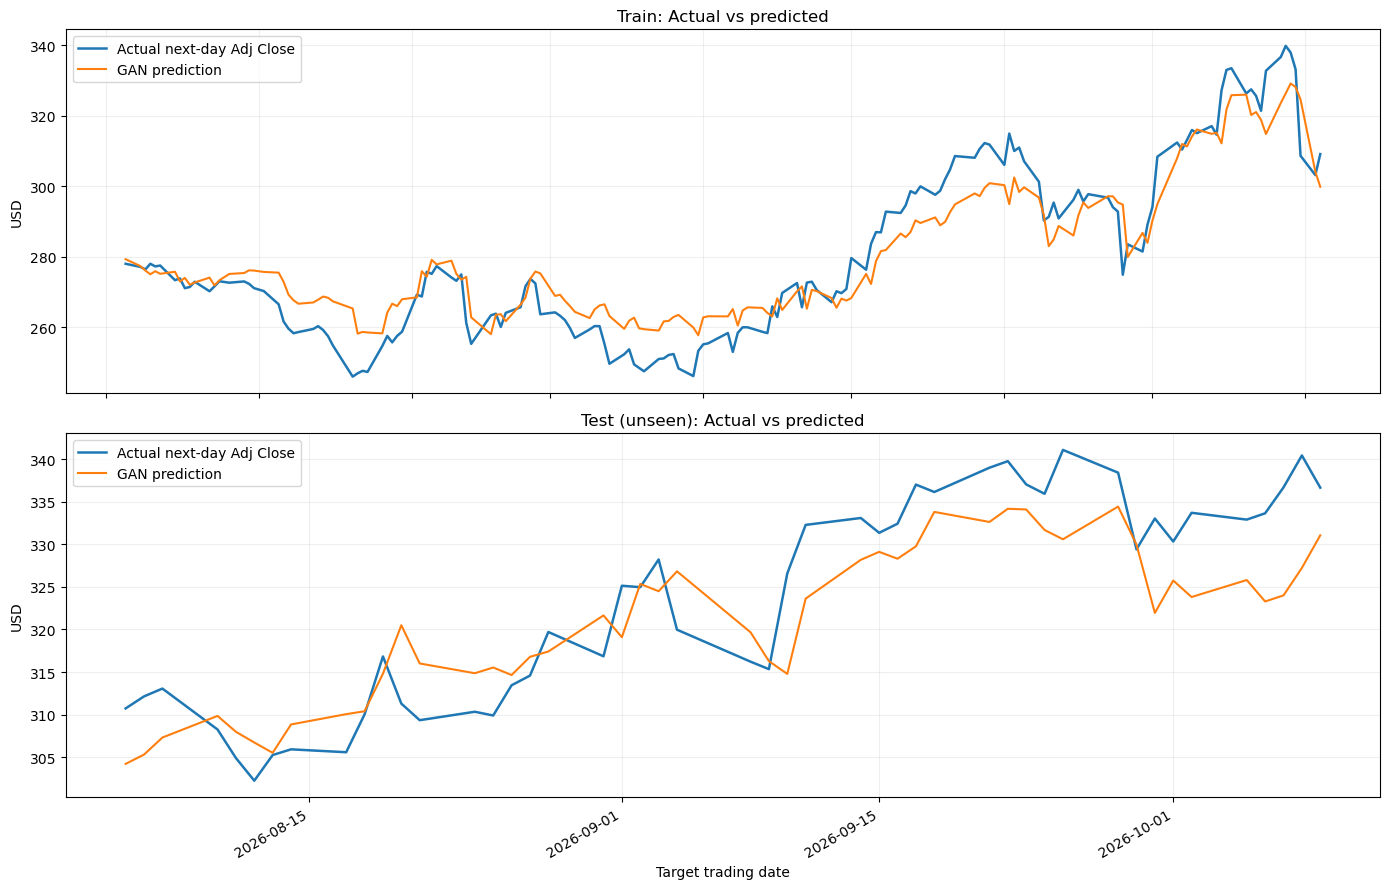

In [23]:
# index arrays refer to row indices in AAPL_GAN_modeling_2025_2026.csv.
modeling=pd.read_csv(DATA_DIR/'AAPL_GAN_modeling_2025_2026.csv',parse_dates=['Date','Target_Date'])
train_dates=modeling.iloc[a['index_train']]['Target_Date'].to_numpy()
test_dates=modeling.iloc[a['index_test']]['Target_Date'].to_numpy()
fig,ax=plt.subplots(2,1,figsize=(14,9))
for axis,dates,actual,pred,label in [(ax[0],train_dates,train_actual,train_pred,'Train'),
                                     (ax[1],test_dates,test_actual,test_pred,'Test (unseen)')]:
    axis.plot(dates,actual,label='Actual next-day Adj Close',lw=1.8)
    axis.plot(dates,pred,label='GAN prediction',lw=1.5)
    axis.set(title=f'{label}: Actual vs predicted',ylabel='USD');axis.legend();axis.grid(alpha=.2)
ax[1].set_xlabel('Target trading date')
fig.autofmt_xdate();plt.tight_layout();plt.show()

## 9 · Compare against no-change baseline and save forecasts

In [24]:
# No-change baseline: tomorrow's adjusted close equals today's adjusted close.
train_baseline=modeling.iloc[a['index_train']]['Adj_Close'].to_numpy(dtype=float)
test_baseline=modeling.iloc[a['index_test']]['Adj_Close'].to_numpy(dtype=float)
comparison=pd.DataFrame({
    'GAN_train_RMSE':[metrics(train_actual,train_pred)['RMSE']],
    'Naive_train_RMSE':[metrics(train_actual,train_baseline)['RMSE']],
    'GAN_test_RMSE':[metrics(test_actual,test_pred)['RMSE']],
    'Naive_test_RMSE':[metrics(test_actual,test_baseline)['RMSE']]})
print(comparison.round(4).to_string(index=False))
comparison.to_csv(MODEL_DIR/'baseline_comparison.csv',index=False)
forecasts=pd.concat([
    pd.DataFrame({'Date':train_dates,'split':'train','Actual':train_actual,'Predicted':train_pred,'Naive':train_baseline}),
    pd.DataFrame({'Date':test_dates,'split':'test','Actual':test_actual,'Predicted':test_pred,'Naive':test_baseline})
],ignore_index=True)
forecasts.to_csv(MODEL_DIR/'predictions.csv',index=False)
print('Saved:',MODEL_DIR.resolve())

 GAN_train_RMSE  Naive_train_RMSE  GAN_test_RMSE  Naive_test_RMSE
         8.0493            4.8625          6.223           4.0102
Saved: /Users/my/Desktop/TWO-LSTM/FinBert_LSTMGRU_GAN/finbert/notebooks/gan_ready/gan_models_20day_previous_close_only
